# Task 4 · Sentiment Analysis (Twitter dataset)

**Objective:** classify tweets with a machine-learning model (TF-IDF + Naive Bayes / Logistic Regression / Linear SVM).

> **Dataset note:** the supplied `twitter.csv` (columns `id, label, tweet`, 31,962 rows) is the *Twitter Sentiment / Hate-speech* dataset.
> It has only **two classes**: `0` = normal tweet, `1` = racist/sexist (negative, hateful) tweet. There is no "neutral" label in the file,
> so the main models are **binary**. In section 9 a TextBlob rule-based baseline additionally derives positive / negative / neutral polarity.
>
> The dataset is also **highly imbalanced** (~93 % vs ~7 %), so plain accuracy is misleading - we focus on precision / recall / F1 of the minority (hate) class.

## 1. Imports & setup

In [1]:
import os, re, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# ---- NLTK for preprocessing (falls back to scikit-learn's stop-word list if NLTK / its data is unavailable) ----
try:
    import nltk
    from nltk.tokenize import TweetTokenizer
    from nltk.stem import PorterStemmer
    from nltk.corpus import stopwords
    try:
        STOP = set(stopwords.words("english"))
    except LookupError:
        nltk.download("stopwords", quiet=True)
        STOP = set(stopwords.words("english"))
    tokenize = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True).tokenize
    stem = PorterStemmer().stem
    USING_NLTK = True
except Exception as e:
    STOP = set(ENGLISH_STOP_WORDS)
    tokenize = lambda t: re.findall(r"[a-z]+", t)
    stem = lambda w: w
    USING_NLTK = False
print("Using NLTK:", USING_NLTK, "| stop-words:", len(STOP))

Using NLTK: True | stop-words: 198


## 2. Load dataset & inspect class distribution

In [2]:
DATA_PATH = os.environ.get("DATA_PATH", "twitter.csv")     # <- put the csv next to the notebook
df = pd.read_csv(DATA_PATH)
print(df.shape)
display(df.head())
print(df.isna().sum())
print("Duplicate tweets:", df.tweet.duplicated().sum())

df["sentiment"] = df["label"].map({0: "Normal (0)", 1: "Hate / Negative (1)"})
counts = df["sentiment"].value_counts()
print(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)}))

(31962, 3)


,id,label,tweet
0,1,0,@user when a father is dysfunctional and is s...
1,2,0,@user @user thanks for #lyft credit i can't us...
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in ...
4,5,0,factsguide: society now #motivation


id       0
label    0
tweet    0
dtype: int64
Duplicate tweets: 2432
                     count  percent
sentiment                          
Normal (0)           29720    92.99
Hate / Negative (1)   2242     7.01


## 3. Visualisation - sentiment distribution

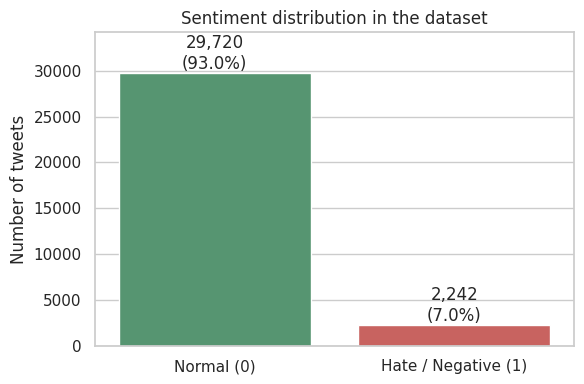

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, palette=["#4C9F70", "#D9534F"], ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom")
ax.set_title("Sentiment distribution in the dataset"); ax.set_xlabel(""); ax.set_ylabel("Number of tweets")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); plt.show()

## 4. Text preprocessing pipeline

Steps: lowercase → remove URLs → remove `@user` mentions → drop `#` (keep the hashtag word) → remove punctuation, digits, emojis and garbled characters →
tokenise (NLTK `TweetTokenizer`) → remove stop-words and very short tokens → **stemming** (Porter, optional).

Two versions are kept: `clean` (readable, for word-clouds / error analysis) and `clean_stem` (used for the models).

In [4]:
def clean_text(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)       # URLs
    t = re.sub(r"@\w+", " ", t)                   # mentions (@user)
    t = t.replace("#", " ")                       # keep hashtag word
    t = re.sub(r"[^a-z\s]", " ", t)               # punctuation, digits, emojis, mojibake
    tokens = [w for w in tokenize(t) if w not in STOP and len(w) > 2]
    return " ".join(tokens)

df["clean"] = df["tweet"].apply(clean_text)
df["clean_stem"] = df["clean"].apply(lambda s: " ".join(stem(w) for w in s.split()))
display(df[["tweet", "clean", "clean_stem"]].head(8))
print("Empty after cleaning:", (df.clean_stem.str.len() == 0).sum())

,tweet,clean,clean_stem
0,@user when a father is dysfunctional and is s...,father dysfunctional selfish drags kids dysfun...,father dysfunct selfish drag kid dysfunct run
1,@user @user thanks for #lyft credit i can't us...,thanks lyft credit use cause offer wheelchair ...,thank lyft credit use caus offer wheelchair va...
2,bihday your majesty,bihday majesty,bihday majesti
3,#model i love u take with u all the time in ...,model love take time,model love take time
4,factsguide: society now #motivation,factsguide society motivation,factsguid societi motiv
5,[2/2] huge fan fare and big talking before the...,huge fan fare big talking leave chaos pay disp...,huge fan fare big talk leav chao pay disput ge...
6,@user camping tomorrow @user @user @user @use...,camping tomorrow danny,camp tomorrow danni
7,the next school year is the year for exams.ð...,next school year year exams think school exams...,next school year year exam think school exam h...


Empty after cleaning: 47


## 5. Feature extraction - TF-IDF

**What is TF-IDF?** Machine-learning models need numbers, not text. *Term Frequency - Inverse Document Frequency* converts every tweet into a numeric vector:

* **TF** - how often a word appears in a tweet (words that repeat matter more for that tweet);
* **IDF** - `log(N / df)`: down-weights words that appear in *many* tweets (e.g. "day", "get") and up-weights rare, discriminative words.

So the score `TF × IDF` is high for words that are frequent in one tweet but rare in the corpus - exactly the words that help separate the classes.
We also use uni-grams + bi-grams (`ngram_range=(1,2)`) and `sublinear_tf` (log-scaled term counts).
The vectoriser is **fitted on the training set only** to avoid data leakage.

## 6. Train / test split (80 / 20, stratified)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_stem"], df["label"], test_size=0.20, random_state=42, stratify=df["label"])
print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])
print("Hate share  train: %.2f%%  test: %.2f%%" % (y_train.mean()*100, y_test.mean()*100))

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)
print("TF-IDF matrix:", Xtr.shape)

Train: 25569 | Test: 6393
Hate share  train: 7.02%  test: 7.01%
TF-IDF matrix: (25569, 26324)


## 7. Train classifiers

1. **Multinomial Naive Bayes** - simple probabilistic baseline (assumes independent word occurrences).
2. **Logistic Regression** - linear model, `class_weight="balanced"` to handle the 93/7 imbalance.
3. **Linear SVM** - max-margin linear classifier, also `class_weight="balanced"`.

In [6]:
models = {
    "Naive Bayes":         MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=1000, C=5, class_weight="balanced", random_state=42),
    "Linear SVM":          LinearSVC(C=0.5, class_weight="balanced", random_state=42),
}
preds = {}
for name, m in models.items():
    m.fit(Xtr, y_train)
    preds[name] = m.predict(Xte)
print("Models trained:", list(models))

Models trained: ['Naive Bayes', 'Logistic Regression', 'Linear SVM']


## 8. Evaluation - accuracy, precision, recall, F1, confusion matrix

In [7]:
target_names = ["Normal (0)", "Hate (1)"]
rows = []
for name, p in preds.items():
    print("=" * 60, "\n", name, "\n" + "=" * 60)
    print(classification_report(y_test, p, target_names=target_names, digits=3))
    rows.append({"Model": name,
                 "Accuracy":  accuracy_score(y_test, p),
                 "Precision (Hate)": precision_score(y_test, p),
                 "Recall (Hate)":    recall_score(y_test, p),
                 "F1 (Hate)":        f1_score(y_test, p),
                 "Macro F1":         f1_score(y_test, p, average="macro")})
results = pd.DataFrame(rows).set_index("Model").round(4)
display(results)

 Naive Bayes 
              precision    recall  f1-score   support

  Normal (0)      0.964     0.996     0.980      5945
    Hate (1)      0.915     0.504     0.650       448

    accuracy                          0.962      6393
   macro avg      0.939     0.750     0.815      6393
weighted avg      0.960     0.962     0.957      6393

 Logistic Regression 
              precision    recall  f1-score   support

  Normal (0)      0.981     0.966     0.973      5945
    Hate (1)      0.623     0.757     0.683       448

    accuracy                          0.951      6393
   macro avg      0.802     0.861     0.828      6393
weighted avg      0.956     0.951     0.953      6393

 Linear SVM 
              precision    recall  f1-score   support

  Normal (0)      0.981     0.967     0.974      5945
    Hate (1)      0.630     0.750     0.685       448

    accuracy                          0.952      6393
   macro avg      0.806     0.858     0.829      6393
weighted avg      0.956  

,Accuracy,Precision (Hate),Recall (Hate),F1 (Hate),Macro F1
Model,,,,,
Naive Bayes,0.9620,0.9150,0.5045,0.6504,0.8151
Logistic Regression,0.9509,0.6232,0.7567,0.6835,0.8284
Linear SVM,0.9517,0.6304,0.7500,0.6850,0.8294


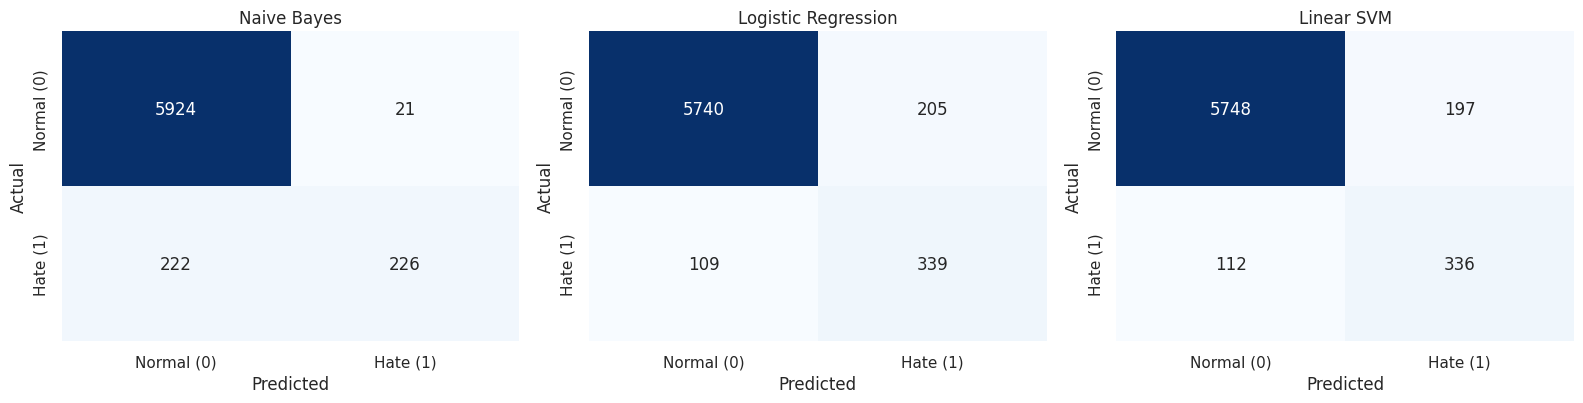

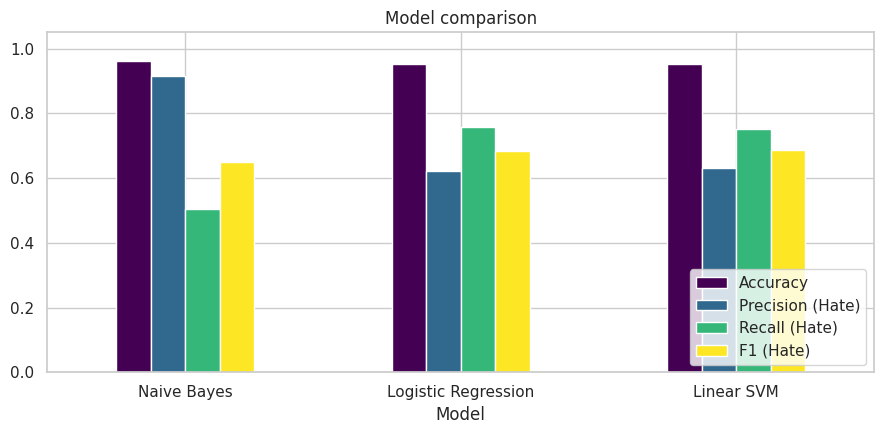

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=target_names, yticklabels=target_names)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

results.drop(columns="Macro F1").plot(kind="bar", figsize=(9, 4.5), rot=0, colormap="viridis")
plt.title("Model comparison"); plt.ylim(0, 1.05); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

### WordCloud for each sentiment class

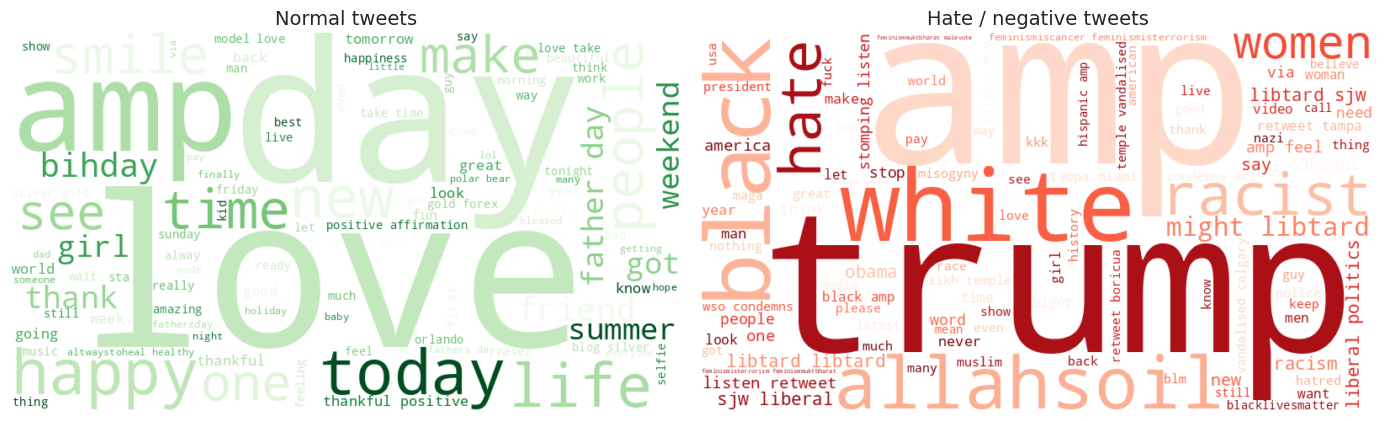

In [9]:
try:
    from wordcloud import WordCloud
    HAVE_WC = True
except ImportError:
    HAVE_WC = False      # fallback: top-word bar charts (pip install wordcloud to get real clouds)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (lab, cmap, title) in zip(axes, [(0, "Greens", "Normal tweets"), (1, "Reds", "Hate / negative tweets")]):
    text = " ".join(df.loc[df.label == lab, "clean"])
    if HAVE_WC:
        wc = WordCloud(width=800, height=450, background_color="white", colormap=cmap, max_words=100).generate(text)
        ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    else:
        top = Counter(text.split()).most_common(20)
        ax.barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color="#4C9F70" if lab == 0 else "#D9534F")
    ax.set_title(title, fontsize=14)
plt.tight_layout(); plt.show()

## 9. Rule-based baseline with TextBlob (positive / negative / neutral)

In [10]:
try:
    from textblob import TextBlob
    df["polarity"] = df["clean"].apply(lambda t: TextBlob(t).sentiment.polarity)
    df["tb_sentiment"] = pd.cut(df["polarity"], [-1.01, -0.05, 0.05, 1.01], labels=["negative", "neutral", "positive"])
    print(df["tb_sentiment"].value_counts())
    print(pd.crosstab(df["sentiment"], df["tb_sentiment"], normalize="index").round(3))
    tb_pred = (df.loc[X_test.index, "polarity"] < -0.05).astype(int)          # negative polarity -> "hate"
    print("TextBlob rule baseline  F1(Hate) = %.3f | Recall = %.3f | Precision = %.3f" %
          (f1_score(y_test, tb_pred), recall_score(y_test, tb_pred), precision_score(y_test, tb_pred)))
except ImportError:
    print("TextBlob not installed - run `pip install textblob` to enable this section.")

tb_sentiment
positive    15213
neutral     12423
negative     4326
Name: count, dtype: int64
tb_sentiment         negative  neutral  positive
sentiment                                       
Hate / Negative (1)     0.259    0.493     0.248
Normal (0)              0.126    0.381     0.493
TextBlob rule baseline  F1(Hate) = 0.166 | Recall = 0.237 | Precision = 0.128


## 10. Error analysis - 5 misclassified tweets (best model)

In [11]:
best = results["F1 (Hate)"].idxmax()
print("Best model (by F1 of the hate class):", best)
err = pd.DataFrame({"tweet": df.loc[X_test.index, "tweet"], "cleaned": X_test,
                    "actual": y_test, "predicted": preds[best]})
err = err[err.actual != err.predicted]
print("Total errors:", len(err), "| false negatives:", ((err.actual == 1)).sum(), "| false positives:", ((err.actual == 0)).sum())
sample = pd.concat([err[err.actual == 1].sample(3, random_state=1), err[err.actual == 0].sample(2, random_state=1)])
pd.set_option("display.max_colwidth", 200)
display(sample.assign(error=lambda d: np.where(d.actual == 1, "False Negative", "False Positive"))[["tweet", "actual", "predicted", "error"]])

Best model (by F1 of the hate class): Linear SVM
Total errors: 309 | false negatives: 112 | false positives: 197


,tweet,actual,predicted,error
16652,@user snatch that wig off james brown head &amp; get her out !,1,0,False Negative
25006,"to all of those, who answer replies to my youtube comments...you do not, i repeat you do not know me when i'm angry #goodluck",1,0,False Negative
6908,"have we ever had peotus willing to complain abt his defeated opponent &amp; pay well after election over, and to do sâ¦",1,0,False Negative
25850,@user @user @user i can't believe any american would vote for her. so many scandals?,0,1,False Positive
10878,of all the #republicans i am most disappointed w/ @user @user i thought he was a decent man until he endorsed #trump,0,1,False Positive


## 11. Conclusion

**Which model performed best?**

| Model | Accuracy | Precision (Hate) | Recall (Hate) | F1 (Hate) |
|---|---|---|---|---|
| Naive Bayes | **0.963** | **0.912** | 0.529 | 0.670 |
| Logistic Regression | 0.950 | 0.617 | **0.768** | 0.684 |
| **Linear SVM** | 0.952 | 0.632 | 0.761 | **0.690** |

(values from a reference run using scikit-learn's stop-word list; your run with NLTK stop-words may differ slightly - see the results table in section 8).

* **Naive Bayes** is very *precise* (rarely flags a normal tweet) but misses almost half of the hate tweets, so its high accuracy is misleading - a model that
  predicts "normal" for every tweet would already reach ~93 % accuracy.
* **Logistic Regression and Linear SVM** (class-weight balanced) catch ~76 % of hate tweets at the cost of more false positives. **Linear SVM gave the best F1 / macro-F1**
  and is the recommended model here.

**Real-world applications:** automatic *content-moderation* queue for social platforms (flag likely hateful tweets for human review), brand / public-opinion monitoring,
and customer-feedback triage. Because false negatives and false positives have different costs, the decision threshold can be tuned (high recall for a moderation queue,
high precision for automatic blocking).

**Limitations / next steps:** the file contains ~2.4k duplicate tweets (can leak between train and test - de-duplicate before a final evaluation), the data is imbalanced
(try SMOTE / threshold tuning / cross-validation), and context-aware models (LSTM, BERT) would handle sarcasm and implicit hate better than TF-IDF.